# Exploració de dades
Exploració de dades inicials. Inclou plots individuals (P0002) i grand average sobre tots els subjectes. Es repliquen els mateixos plots que a l'article de Binocular Rivarly: Evaluating the Role of Theta Power as 
a Neural Index of Conflict (A. Drew, J. San-Segundo, S. Soto-Faraco, M. Torralba Cuello), entre altres.

In [87]:
import sys
from pathlib import Path
from google.colab import drive

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    drive.mount("/content/drive")
    possible_paths = [
        Path("/content/drive/Shareddrives/TFG_Nils_2026"),
        Path("/content/drive/MyDrive/TFG_Nils_2026"),
    ]
    BASE_DIR = next((p for p in possible_paths if p.exists()), possible_paths[0])
    DATA_DIR = BASE_DIR / "02_Data" / "01_Preprocessed_epochs"
    META_DIR = BASE_DIR / "02_Data" / "02_meta"
else:
    BASE_DIR = Path(".").resolve()
    DATA_DIR = BASE_DIR / "data"
    META_DIR = BASE_DIR / "docs"

print(f"Entorn : {'Colab' if IN_COLAB else 'Local'}")
print(f"Dades  : {DATA_DIR} → {'✅' if DATA_DIR.exists() else '❌'}")
if DATA_DIR.exists():
    fitxers = sorted(DATA_DIR.glob("*.fif"))
    print(f"Subjectes disponibles ({len(fitxers)}): {[f.name for f in fitxers]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorn : Colab
Dades  : /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs → ✅
Subjectes disponibles (47): ['P0002.fif', 'P0003.fif', 'P0004.fif', 'P0005.fif', 'P0009.fif', 'P008.fif', 'P010.fif', 'P011.fif', 'P013.fif', 'P014.fif', 'P015.fif', 'P016.fif', 'P017.fif', 'P020.fif', 'P021.fif', 'P022.fif', 'P023.fif', 'P024.fif', 'P025.fif', 'P027.fif', 'P028.fif', 'P029.fif', 'P030.fif', 'P031.fif', 'P033.fif', 'P035.fif', 'P039.fif', 'P040.fif', 'P041.fif', 'P044.fif', 'P045.fif', 'P046.fif', 'P048.fif', 'P051.fif', 'P053.fif', 'P056.fif', 'P057.fif', 'P058.fif', 'P060.fif', 'P061.fif', 'P062.fif', 'P063.fif', 'P065.fif', 'P066.fif', 'P067.fif', 'P068.fif', 'P069.fif']


In [88]:
%pip install -q mne

import mne
import numpy as np
import matplotlib.pyplot as plt
from mne.time_frequency import tfr_morlet
from matplotlib.patches import Rectangle
import warnings

# Filtrem només l'avís que conté el text sobre les convencions de noms de fitxers
warnings.filterwarnings(
    'ignore', 
    category=RuntimeWarning, 
    module='mne', 
    message=".*does not conform to MNE naming conventions.*"
)

mne.set_log_level('WARNING')

In [89]:
# Paràmetres globals

# Agrupació d'events: els noms al fitxer són 'event_1', 'event_2', ...
# Left eye | Right eye | Response | Codi
#   Red    |   Red     |  Red     |  1  → Congruent
#   Green  |   Green   |  Green   |  2  → Congruent
#   Red    |   Green   |  Red     |  3  → Incongruent Pur
#   Green  |   Red     |  Red     |  4  → Incongruent Pur
#   Red    |   Green   |  Green   |  5  → Incongruent Pur
#   Green  |   Red     |  Green   |  6  → Incongruent Pur
#   Red    |   Green   |  Both    |  7  → Incongruent Mixt
#   Green  |   Red     |  Both    |  8  → Incongruent Mixt
#   9–12                               → Errors (ignorats)

COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent_Pur": ["event_3", "event_4", "event_5", "event_6"],
    "Incongruent_Mixt": ["event_7", "event_8"],
}

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

# Finestres de temps
TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
RAMP_UP = (-0.24, 0.0)
STIM_ONSET = (0.0, 1.5)
STIM_OFFSET = (1.5, 2.0)

FINESTRA_1 = (0.0, 0.5)
FINESTRA_2 = (0.5, 1.0)
FINESTRA_3 = (1.0, 1.5)

COLORS = {"Congruent": "steelblue", "Incongruent_Pur": "darkorange", "Incongruent_Mixt": "forestgreen"}
LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pur": "Incongruent Pur (IP)",
    "Incongruent_Mixt": "Incongruent Mixt (IM)",
}

FREQS_THETA = np.arange(5, 8, 1)
FREQS_ALPHA = np.arange(8, 13, 1)
FREQS_WIDE = np.arange(2, 21, 1)
N_CYCLES_T = FREQS_THETA / 2.0
N_CYCLES_A = FREQS_ALPHA / 2.0
N_CYCLES_W = FREQS_WIDE / 2.0

In [90]:
# ── Funció de càrrega reutilitzable ───────────────────────────────────────────
def load_subject(fif_path):
    """Carrega un .fif, corregeix els tipus de canal i retorna epochs_all + epochs_cond."""
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    # Corregir unitats i tipus (surten com a 'misc' del preprocessat)
    for ch in ep.info["chs"]:
        ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

    cond = {}
    for cond_name, event_names in COND_EVENTS.items():
        existing = [n for n in event_names if n in ep.event_id]
        if existing:
            cond[cond_name] = ep[existing]
    return ep, cond

---

## Part 1: Exploració individual (P0002)
Començo amb un sol participant/subjecte per familiaritzar-me amb les dades i fer plots senzills. Després passaré a fer el grand average amb tots els subjectes.

In [91]:
SUBJ = "P0002"
epochs_all, epochs_cond = load_subject(DATA_DIR / f"{SUBJ}.fif")

print(f"Temps   : {epochs_all.tmin:.3f} → {epochs_all.tmax:.3f} s")
print(f'Mostreig: {epochs_all.info["sfreq"]} Hz  |  Canals: {len(epochs_all.ch_names)}')
for cond, ep in epochs_cond.items():
    print(f"  {cond:20s}: {len(ep):3d} trials")

Temps   : -1.240 → 2.000 s
Mostreig: 500.0 Hz  |  Canals: 60
  Congruent           : 144 trials
  Incongruent_Pur     : 133 trials
  Incongruent_Mixt    : 107 trials


### ERP (temps vs. voltatge)
Senyal promig ± SEM per Fz, FCz, Cz. Serveix com a sanity check: si l'estímul produeix una resposta evocada clara i coherent entre condicions, les dades estan bé.

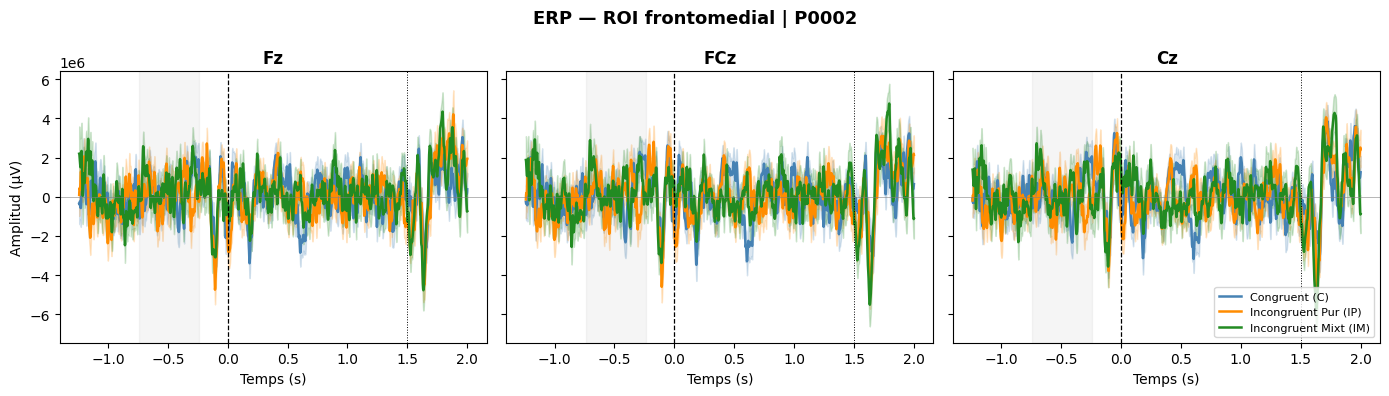

In [92]:
fig, axes = plt.subplots(1, len(ROI_FRONTAL), figsize=(14, 4), sharey=True)
times = epochs_all.times

for ax, ch in zip(axes, ROI_FRONTAL):
    for cond, ep in epochs_cond.items():
        data = ep.get_data(picks=[ch]).squeeze() * 1e6
        mean, sem = data.mean(axis=0), data.std(axis=0) / np.sqrt(len(ep))
        ax.plot(times, mean, label=LABELS[cond], color=COLORS[cond], linewidth=1.8)
        ax.fill_between(times, mean - sem, mean + sem, color=COLORS[cond], alpha=0.2)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.7)
    ax.axhline(0, color="gray", linewidth=0.4)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08)
    ax.set_title(ch, fontsize=12, fontweight="bold")
    ax.set_xlabel("Temps (s)")

axes[0].set_ylabel("Amplitud (µV)")
axes[-1].legend(fontsize=8, loc="lower right")
fig.suptitle(f"ERP — ROI frontomedial | {SUBJ}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Theta power time-course (temps vs. potència, dB)
Potència theta (5–7 Hz) baseline-corregida, promig sobre Fz/FCz/Cz.
**Aquest és el plot central del TFG**: si el conflicte activa el sistema de monitoratge, IP ha de mostrar més potència theta que C durant la presentació de l'estímul.
Equivalent a la Figura 2B de l'article.

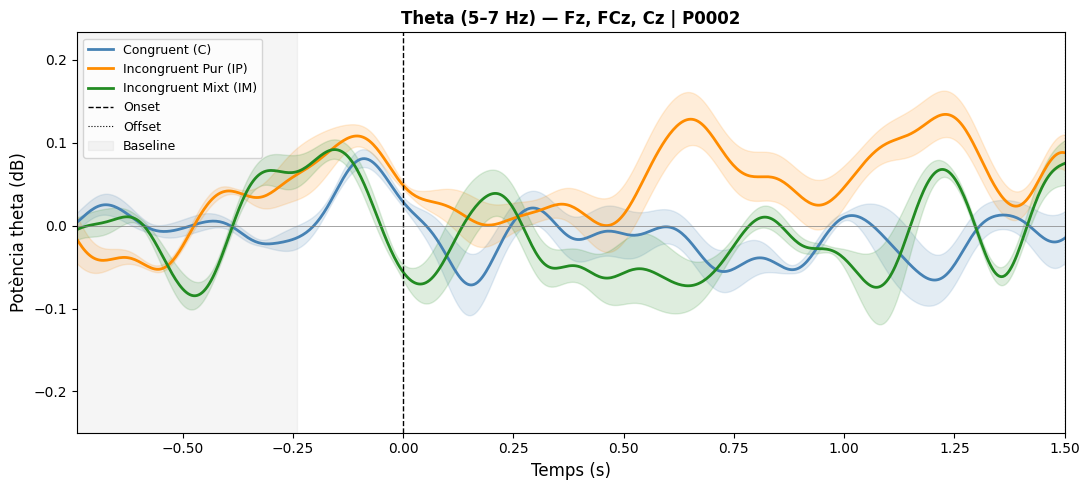

In [93]:
tfr_theta = {}
for cond, ep in epochs_cond.items():
    tfr = tfr_morlet(
        ep.copy().pick(ROI_FRONTAL),
        freqs=FREQS_THETA,
        n_cycles=N_CYCLES_T,
        return_itc=False,
        average=True,
        decim=2,
        n_jobs=1,
    )
    tfr.apply_baseline(baseline=BASELINE, mode="logratio")
    tfr_theta[cond] = tfr

fig, ax = plt.subplots(figsize=(11, 5))
for cond, tfr in tfr_theta.items():
    power_ts = tfr.data.mean(axis=(0, 1))
    sem_ts = tfr.data.std(axis=(0, 1)) / np.sqrt(tfr.data.shape[0])
    ax.plot(tfr.times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(tfr.times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència theta (dB)", fontsize=12)
ax.set_title(f"Theta (5–7 Hz) — Fz, FCz, Cz | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.show()

### TFR map diferencial. Figura 3 (A i C)
Diferència de potència (IP−C i IP−IM) per tot l'espectre i tots els elèctrodes. 
Vermell = més potència en IP; blau = menys. Les bandes theta i alpha marcades.

/tmp/ipykernel_266/4167187841.py:33: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axhspan(8, 12, color="white", alpha=0.15, edgecolor="white", linewidth=1.5)
/tmp/ipykernel_266/4167187841.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


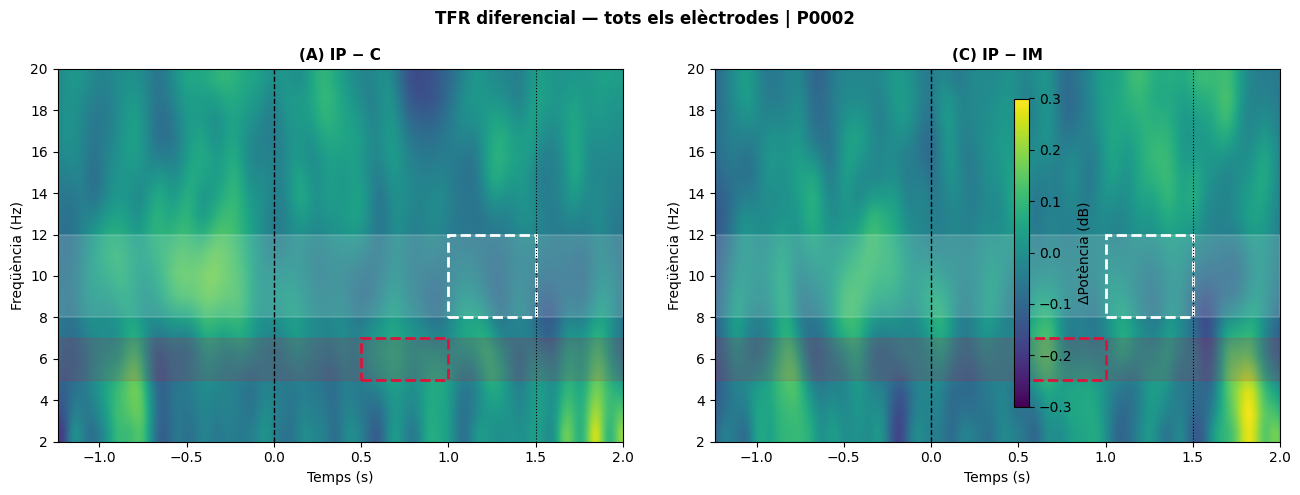

In [94]:
tfr_all_ch = {}
for cond, ep in epochs_cond.items():
    tfr = tfr_morlet(
        ep.copy(), freqs=FREQS_WIDE, n_cycles=N_CYCLES_W, return_itc=False, average=True, decim=2, n_jobs=1
    )
    tfr.apply_baseline(baseline=BASELINE, mode="logratio")
    tfr_all_ch[cond] = tfr

VLIM = 0.3
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]
for ax, (panel, ca, cb, title) in zip(axes, contrasts):
    diff = tfr_all_ch[ca].data.mean(axis=0) - tfr_all_ch[cb].data.mean(axis=0)
    # Remove horizontal gradients by subtracting the mean across time at each frequency
    diff = diff - diff.mean(axis=1, keepdims=True)
    t = tfr_all_ch[ca].times
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        extent=[t[0], t[-1], FREQS_WIDE[0], FREQS_WIDE[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="bilinear",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.15)
    ax.axhspan(8, 12, color="white", alpha=0.15, edgecolor="white", linewidth=1.5)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="white", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")

fig.colorbar(im, ax=axes.tolist(), label="ΔPotència (dB)", shrink=0.8)
fig.suptitle(f"TFR diferencial — tots els elèctrodes | {SUBJ}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### Alpha suppression. Figura 4A
Potència alpha (8–12 Hz) sobre ROI parieto-occipital. Supressió alpha = major activació visual.
Hipòtesi: IP i IM haurien de mostrar més supressió (valors més baixos) que C.

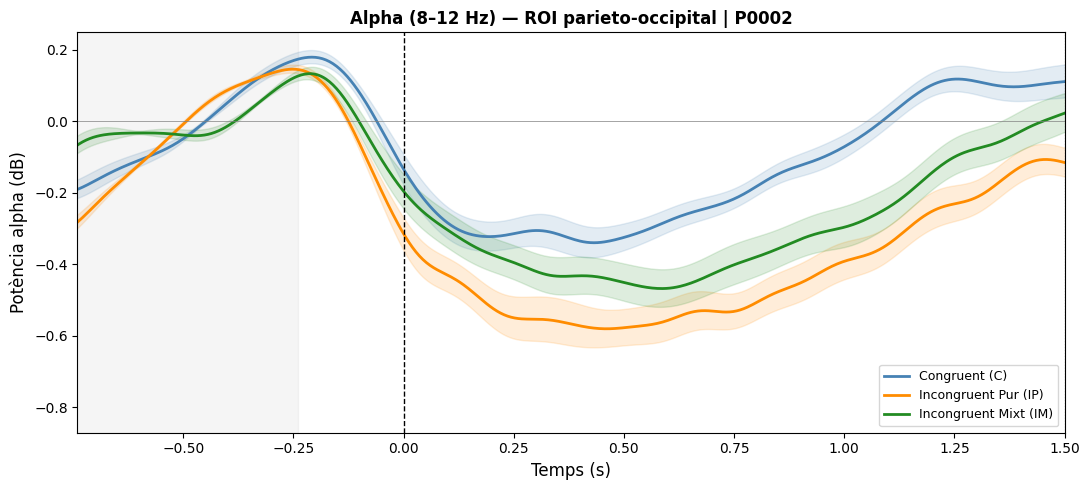

In [95]:
tfr_alpha = {}
for cond, ep in epochs_cond.items():
    po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
    tfr = tfr_morlet(
        ep.copy().pick(po_ok), freqs=FREQS_ALPHA, n_cycles=N_CYCLES_A, return_itc=False, average=True, decim=2, n_jobs=1
    )
    tfr.apply_baseline(baseline=BASELINE, mode="logratio")
    tfr_alpha[cond] = tfr

fig, ax = plt.subplots(figsize=(11, 5))
for cond, tfr in tfr_alpha.items():
    power_ts = tfr.data.mean(axis=(0, 1))
    sem_ts = tfr.data.std(axis=(0, 1)) / np.sqrt(tfr.data.shape[0])
    ax.plot(tfr.times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(tfr.times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència alpha (dB)", fontsize=12)
ax.set_title(f"Alpha (8–12 Hz) — ROI parieto-occipital | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.show()

---

## Part 2: Mitjana sobre tots els subjectes

El loop carrega cada subjecte, calcula els TFRs theta i alpha, i acumula els time-courses.
Al final es fa la mitjana entre subjectes i es reploten els mateixos gràfics amb SEM real entre subjectes.

In [ ]:
# Acumuladors
all_theta = {cond: [] for cond in COND_EVENTS}
all_alpha = {cond: [] for cond in COND_EVENTS}
subjectes_inclosos, subjectes_exclosos = [], []
times_ga = None

def power_ts(ep, picks, freqs, n_cycles):
    tfr = tfr_morlet(
        ep.copy().pick(picks),
        freqs=freqs,
        n_cycles=n_cycles,
        return_itc=False,
        average=True,
        decim=2,
        n_jobs=1,
        verbose=False,
    )
    tfr.apply_baseline(baseline=BASELINE, mode="logratio")
    return tfr.times, tfr.data.mean(axis=(0, 1))  # (n_times,)

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    try:
        _, ep_cond = load_subject(fif_path)
    except Exception as e:
        print(f"  ⚠️  {subj_id}: error en càrrega → {e}")
        subjectes_exclosos.append(subj_id)
        continue

    for cond, ep in ep_cond.items():
        # Theta (ROI frontal)
        t, ts = power_ts(ep, ROI_FRONTAL, FREQS_THETA, N_CYCLES_T)
        all_theta[cond].append(ts)
        if times_ga is None:
            times_ga = t

        # Alpha (ROI parieto-occipital)
        po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
        if po_ok:
            _, ts = power_ts(ep, po_ok, FREQS_ALPHA, N_CYCLES_A)
            all_alpha[cond].append(ts)

    subjectes_inclosos.append(subj_id)

print(f"\nInclosos : {len(subjectes_inclosos)} — {subjectes_inclosos}")
print(f"Exclosos : {len(subjectes_exclosos)} — {subjectes_exclosos}")


Inclosos : 47 — ['P0002', 'P0003', 'P0004', 'P0005', 'P0009', 'P008', 'P010', 'P011', 'P013', 'P014', 'P015', 'P016', 'P017', 'P020', 'P021', 'P022', 'P023', 'P024', 'P025', 'P027', 'P028', 'P029', 'P030', 'P031', 'P033', 'P035', 'P039', 'P040', 'P041', 'P044', 'P045', 'P046', 'P048', 'P051', 'P053', 'P056', 'P057', 'P058', 'P060', 'P061', 'P062', 'P063', 'P065', 'P066', 'P067', 'P068', 'P069']
Exclosos : 0 — []


### Theta power time-course
Cada línia és la mitjana entre subjectes. L'àrea ombrejada és el SEM entre subjectes (no entre trials ni entre canals com en els plots individuals).

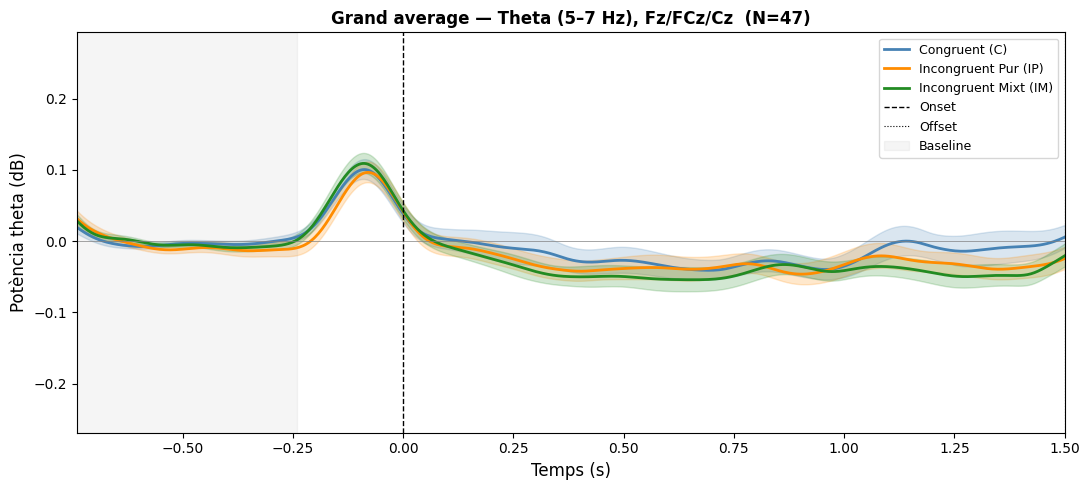

In [97]:
def plot_timecourse_ga(accumulator, times, ylabel, title):
    """Plot de grand average amb SEM entre subjectes."""
    fig, ax = plt.subplots(figsize=(11, 5))
    n_subj = len(next(iter(accumulator.values())))

    for cond, ts_list in accumulator.items():
        mat = np.array(ts_list)  # (n_subjectes, n_times)
        mean_ga = mat.mean(axis=0)
        sem_ga = mat.std(axis=0) / np.sqrt(len(ts_list))
        ax.plot(times, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
        ax.fill_between(times, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
    ax.set_xlabel("Temps (s)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f"{title}  (N={n_subj})", fontsize=12, fontweight="bold")
    ax.set_xlim(FULL_TRIAL)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


plot_timecourse_ga(
    all_theta,
    times_ga,
    ylabel="Potència theta (dB)",
    title="Grand average — Theta (5–7 Hz), Fz/FCz/Cz",
)

### Alpha suppression

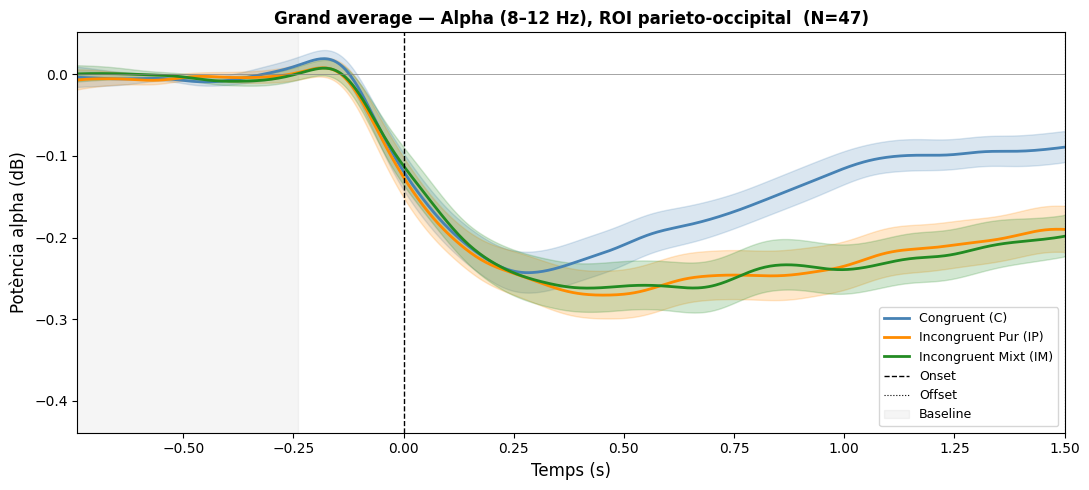

In [98]:
plot_timecourse_ga(
    all_alpha,
    times_ga,
    ylabel="Potència alpha (dB)",
    title="Grand average — Alpha (8–12 Hz), ROI parieto-occipital",
)

### ERP (Event-Related Potential)
Mitjana del senyal en el domini temporal. Aquí cal recalcular perquè necessitem les dades en brut (µV), no els TFRs.

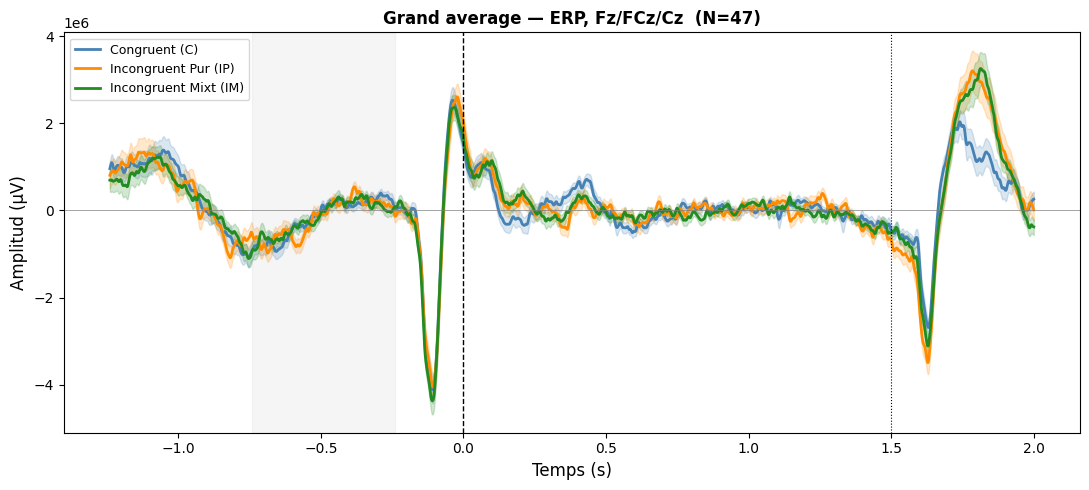

In [99]:
all_erp = {cond: [] for cond in COND_EVENTS}  # (n_subjectes, n_times) per canal promig
times_erp = None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjectes_inclosos:
        continue
    ep_all, ep_cond = load_subject(fif_path)
    if times_erp is None:
        times_erp = ep_all.times
    for cond, ep in ep_cond.items():
        # Promig sobre trials i sobre canals ROI → (n_times,)
        data = ep.get_data(picks=ROI_FRONTAL).mean(axis=0).mean(axis=0) * 1e6
        all_erp[cond].append(data)

fig, ax = plt.subplots(figsize=(11, 5))
n_subj = len(subjectes_inclosos)
for cond, ts_list in all_erp.items():
    mat = np.array(ts_list)
    mean_ga = mat.mean(axis=0)
    sem_ga = mat.std(axis=0) / np.sqrt(n_subj)
    ax.plot(times_erp, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times_erp, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Amplitud (µV)", fontsize=12)
ax.set_title(f"Grand average — ERP, Fz/FCz/Cz  (N={n_subj})", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()